**!!! IMPORTANT NOTE !!!** : All output generated from this notebook can be find in **[here](https://drive.google.com/drive/folders/1RDw2wUKpYiQyIx8HCfeP5DRVOkulhwFP?usp=drive_link)**

# SETUP & PRE-PROCESSING

## **1. Project Setup and Data Loading**

### Package Installation

In [ ]:
import sys
!{sys.executable} -m ipykernel install --user --name=python310forpycaret --display-name "ECHR PyCaret (Python 3.10)"

%pip install gdown
%pip install pycaret


Installed kernelspec python310forpycaret in /Users/rini/Library/Jupyter/kernels/python310forpycaret
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import re
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# Visualization
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

# Sklearn — RQ1: Text & Metadata Classification
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
# metadata baseline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate
from sklearn.manifold import TSNE

# Sklearn — RQ2 & RQ3: Topic Modelling + Country Bias
from sklearn.decomposition import NMF, TruncatedSVD
# NMF = primary, TruncatedSVD = optional
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance
# Importing permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

# Sklearn — RQ3 & future RQs: Cosine Similarity + Dimensionality Reduction
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# Gensim — RQ4: Word2Vec (Margin of Appreciation)
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Theme
PALETTE = {
    'Violation':    '#CC5441',
    'No Violation': '#A0E3E8'
}
CMAP = 'Blues'
sns.set_theme(style='whitegrid')
sns.set_palette([PALETTE['Violation'], PALETTE['No Violation']])

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [ ]:
import gdown
from pycaret.classification import setup, compare_models, pull, predict_model

### Data Loading and Preprocessing

**Data Source & Validation Summary**

Primary Source: Data was originally sourced from [echr-opendata.eu](https://echr-opendata.eu). The site provides several kinds of pre-processed data. For this project, we use *"unstructured cases in JSON".*

**Current Status**

While the primary source website currently returns a "502 Bad Gateway" error, a stable local version of the dataset was successfully archived as of 9 February 2026.

**Temporal Scope**

The dataset provides comprehensive coverage of Article 8 cases from the Court's inception through 2023. We use data related to Article 8, from 2010 - 2023.

**Integrity Verification**

To ensure the reliability of the JSON data, random sampling was conducted to compare the archived local files against the official HUDOC (ECHR) database.  Cross-referencing confirmed that the text sections and metadata in the JSON files are **identical** to the official records, validating the dataset's accuracy for high-importance legal analysis.

*Other documentation:* [Github](https://github.com/echr-od/ECHR-OD_process)

### Download Raw Data

In [ ]:
# Download and load raw data
if not os.path.exists('echr_raw.json'):
    FILE_ID = '10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX'
    gdown.download(id=FILE_ID, output='echr_raw.json', quiet=False)

df_raw = pd.read_json('echr_raw.json')
df_raw['date_dt'] = pd.to_datetime(df_raw['judgementdate'], dayfirst=True, errors='coerce')
df_raw['year'] = df_raw['date_dt'].dt.year

# Filter Article 8 cases 2010-2023
def mentions_article_8(val):
    if isinstance(val, list):
        return '8' in [str(x).strip() for x in val]
    if isinstance(val, str):
        return '8' in [x.strip() for x in val.replace(',', ';').split(';')]
    return False

art_col = 'article' if 'article' in df_raw.columns else '__articles'
mask_art8 = df_raw[art_col].apply(mentions_article_8)
mask_year = df_raw['year'].between(2010, 2023)

df_art8 = df_raw[mask_art8 & mask_year][[
    'itemid',
    'docname',
    'conclusion',
    'content',
    'respondent',            # respondent state
    'year',                  # temporal signal
    'importance',            # case weight (1–4)
    'originatingbody_type',  # Section vs. Grand Chamber
    'typedescription',       # judgment vs. decision type
    'languageisocode',       # language artefact control
    'separateopinion',
    'date_dt'       # dissent flag — contested cases
]].copy()

# Feature engineering
df_art8['has_dissent']  = df_art8['separateopinion'].notna().astype(int)
df_art8['is_english']   = (df_art8['languageisocode'] == 'ENG').astype(int)
df_art8['importance']   = df_art8['importance'].astype(str)

# Modified: Ensure respondent_country only contains one country
df_art8['respondent'] = df_art8['respondent'].astype(str).apply(lambda x: x.split(';')[0].strip() if ';' in x else x.strip())
df_art8['originatingbody_type'] = df_art8['originatingbody_type'].astype(str)
df_art8['typedescription']      = df_art8['typedescription'].astype(str)

df_art8 = df_art8.rename(columns={
    'docname':              'title',
    'conclusion':           'conclusion_structured',
    'content':              'full_text',
    'respondent':           'respondent_country',
    'originatingbody_type': 'court'
})

print(f'Article 8 cases (2010-2023): {len(df_art8):,}')

Article 8 cases (2010-2023): 1,321


In [ ]:
SAVE_PATH = "./output/"
os.makedirs(SAVE_PATH, exist_ok=True)

## **2. Feature Engineering**

### Text Extraction

The raw dataset contains 1,321 Article 8 cases with a severe 3.5:1 class imbalance (982 violations to 283 non-violations). This ~77.7% violation rate is not a sampling error, but the institutional reality of the ECHR's strict admissibility filter pre-screening weak cases. Because a naive baseline model could achieve 77% accuracy simply by guessing "Violation" every time, we rely on Macro F1 and balanced class weights to evaluate true predictive power.

During preprocessing, 56 cases flagged as "Only Mentioning" were explicitly filtered out of the dataset. These represent judgments that were settled via Just Satisfaction or struck out without a substantive ruling on the merits. Removing them leaves exactly 1,265 usable binary cases (Violation vs. No Violation) for our machine learning classifiers.

In [ ]:
# Recursive content extractor
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

def extract_section_text(full_text_entry, sections_to_include=None, sections_to_exclude=None):
    if not isinstance(full_text_entry, dict):
        return str(full_text_entry) if full_text_entry else ''
    all_text = []
    for doc_key, sections_list in full_text_entry.items():
        if isinstance(sections_list, list):
            for section in sections_list:
                if isinstance(section, dict):
                    section_name = section.get('section_name', '').lower().strip()
                    if sections_to_include and section_name not in sections_to_include:
                        continue
                    if sections_to_exclude and section_name in sections_to_exclude:
                        continue
                    all_text.extend(extract_content_recursive(section))
    return ' '.join(all_text)

def extract_best_available_text(full_text_entry):
    """Extract facts + law text, falling back to full text for non-standard cases."""
    facts = extract_section_text(full_text_entry, sections_to_include=['facts','relevant_law'])
    law   = extract_section_text(full_text_entry, sections_to_include=['law'])
    combined = ' '.join([facts, law]).strip()
    if len(combined.split()) < 50:
        return extract_section_text(
            full_text_entry,
            sections_to_exclude=['toc', 'appendix', 'conclusion']
        )
    return combined

# Helper function to remove numbers and symbols from text
def clean_text_for_tfidf(text):
    text = re.sub(r'[^a-z\s]', '', text.lower()) # Keep only lowercase letters and spaces
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces
    return text

df_art8['analysis_text'] = df_art8['full_text'].apply(extract_best_available_text)
# Apply cleaning to analysis_text immediately after extraction
df_art8['analysis_text'] = df_art8['analysis_text'].apply(clean_text_for_tfidf)
print(f"Text extracted. Mean word count: {df_art8['analysis_text'].apply(lambda x: len(x.split())).mean():,.0f}")

# Print 2 examples of extracted 'analysis_text'
print('\n--- Example 1 of Facts Section ---')
print(clean_text_for_tfidf(extract_section_text(df_art8['full_text'].iloc[0], sections_to_include=['facts', 'relevant_law']))[:500] + '...')

# Print first 500 characters for brevity
print('\n--- Example 2 of Law Section ---')
print(clean_text_for_tfidf(extract_section_text(df_art8['full_text'].iloc[1], sections_to_include=['law']))[:500] + '...')

# Extract facts and law sections into new columns
df_art8['facts_text'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['facts', 'relevant_law']))
df_art8['law_text'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['law']))

# *** NEW: Create a raw version of law_text for Word2Vec that retains punctuation ***
df_art8['law_text_w2v_raw'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['law']))

# Apply cleaning to facts_text and law_text
df_art8['facts_text'] = df_art8['facts_text'].apply(clean_text_for_tfidf)
df_art8['law_text'] = df_art8['law_text'].apply(clean_text_for_tfidf)

# Placeholder for 'law_text_clean' for the leakage test variant (V3)
# If specific 'remedies language' needs to be removed, this line should be modified.
df_art8['law_text_clean'] = df_art8['law_text'].copy()

# Calculate and print mean and median word counts for facts and law sections
print(f"\nMean word count for Facts Section: {df_art8['facts_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Facts Section: {df_art8['facts_text'].apply(lambda x: len(x.split())).median():,.0f}")
print(f"\nMean word count for Law Section: {df_art8['law_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Law Section: {df_art8['law_text'].apply(lambda x: len(x.split())).median():,.0f}")
print(f"\nMean word count for Combined Section: {df_art8['analysis_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Combined Section: {df_art8['analysis_text'].apply(lambda x: len(x.split())).median():,.0f}")

Text extracted. Mean word count: 8,651

--- Example 1 of Facts Section ---
the facts i the circumstances of the case a application no zubkov v russia on april the local police sent to the local investigations committee audio recordings of telephone conversations between the applicant and several persons and video recordings of their meetings in a flat in novgorod the accompanying letter which the government presented to the court stated that the audio and video recordings had been obtained in the course of covert operationalsearch measures authorised by the president o...

--- Example 2 of Law Section ---
the law i alleged violation of articles and of the convention the applicant complained that the state had failed to properly investigate the alleged rape the court considers that the complaint falls to be examined under articles and of the convention which in so far as relevant read as follows article no one shall be subjected to torture or to inhuman or degrading treatment or punishm

### Outcome Extraction

In [ ]:
import ast

def extract_finding_structured(conclusion_list):
    """Extract Article 8 finding from the structured conclusion column."""
    # Try to convert string representations of lists/dicts into actual Python objects
    if isinstance(conclusion_list, str):
        try:
            conclusion_list = ast.literal_eval(conclusion_list)
        except (ValueError, SyntaxError):
            return 'Only Mentioning' # Not a valid string representation of a list/dict

    if not isinstance(conclusion_list, list):
        return 'Only Mentioning'
    for item in conclusion_list:
        if not isinstance(item, dict):
            continue
        is_art8 = (
            item.get('base_article') == '8' or
            item.get('article') == '8' or
            re.search(r'art(icle)?\.?\s*8', str(item.get('element', '')), re.IGNORECASE))

        if is_art8:
            if item.get('type') == 'violation':
                return 'Violation'
            elif item.get('type') == 'no-violation':
                return 'No Violation'
    return 'Only Mentioning'

df_art8['finding'] = df_art8['conclusion_structured'].apply(extract_finding_structured)

print('Outcome distribution (df_art8):')
print(df_art8['finding'].value_counts())

Outcome distribution (df_art8):
finding
Violation          982
No Violation       283
Only Mentioning     56
Name: count, dtype: int64


### Legal Stop Words and English Stop Words

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

def clean_stop_words_list(word_list):
    cleaned_list = []
    for word in word_list:
        # Remove numbers and symbols, keep only alphabetic characters
        cleaned_word = re.sub(r'[^a-z]', '', word.lower())
        if cleaned_word: # Only add if not empty after cleaning
            cleaned_list.append(cleaned_word)
    return cleaned_list

# --- Legal & Procedural Boilerplate ---
legal_procedural = [
    'read', 'conjunction', 'separately', 'preliminary', 'remainder', 'taken',
    'regarding', 'respective', 'respect', 'pursuant', 'herein', 'therein',
    'thereof', 'whereas', 'hereby', 'aforementioned', 'abovementioned',
    'inter', 'alia', 'mutatis', 'mutandis', 'prima', 'facie', 'application',
    'applicant', 'court', 'article', 'paragraph', 'section', 'case', 'matter',
    'judgment', 'decision', 'chamber', 'grand', 'respondent', 'government',
    'state', 'commission', 'protocol', 'convention', 'echr'
]
legal_procedural = clean_stop_words_list(legal_procedural)

# --- Article 8 Universal Framing Terms ---
# Appear in nearly every Art. 8 case regardless of outcome — low discriminative value
art8_universal = [
    'private', 'family', 'democratic', 'society', 'legitimate',  'aim', 'authority', 'domestic', 'national'
]
art8_universal = clean_stop_words_list(art8_universal)

# --- Facts Section Structural Artifacts ---
# Appear in Facts section formatting, not substantive content
facts_specific_noise = [
    'international', 'text', 'introduction', 'comparative', 'relevant',
    'material', 'appended', 'table', 'list', 'set', 'complained',
    'complaint', 'raised', 'provision','interference'
]
facts_specific_noise = clean_stop_words_list(facts_specific_noise)

# Remedies vocabulary — outcome-leaking terms specific to Law section
remedies_leakage = [
    'damage', 'damages', 'eur', 'costs', 'satisfaction',
    'award', 'reimburse', 'reimbursement', 'pecuniary',
    'non-pecuniary', 'just', 'compensation', 'penalty',
    'fine', 'euros', 'sum', 'paid', 'payable','violation', 'breach', 'infringement', 'complied', 'upheld',
    'dismissed', 'allowed', 'inadmissible', 'admissible', 'non', 'struck',
    'reparation','injured','contracting','partial','incurred','expenses','default','rate','afford','allows', "party", "high", "concerned", "internal"]
remedies_leakage = clean_stop_words_list(remedies_leakage)

# -----------------------------------------------------------------------
# Combined Stop Word Lists — one per text column
# -----------------------------------------------------------------------

# Shared foundation
base_stop_words = (
    list(ENGLISH_STOP_WORDS) +
    legal_procedural +
    art8_universal
)

# RQ1 primary text variant — fairest comparison against metadata
custom_facts_stop_words = base_stop_words + facts_specific_noise

# RQ1 diagnostic leakage variant + RQ4 Word2Vec training corpus
custom_law_stop_words = base_stop_words

# RQ1 leakage test variant (V3) - for 'law_text_clean'


# V3 Law Clean — base + remedies stripped
custom_law_clean_stop_words = base_stop_words + remedies_leakage

# For RQ4 Word2Vec focal terms

custom_w2v_stop_words = (
    list(ENGLISH_STOP_WORDS) +
    legal_procedural
)
# Remove the specific focal terms from the custom_w2v_stop_words list if they accidentally got added

custom_w2v_stop_words = [word for word in custom_w2v_stop_words if 'w2v_focal_terms_to_retain' not in locals() or word not in w2v_focal_terms_to_retain]
custom_analysis_stop_words = base_stop_words


print('Stop word lists built.')
print(f'  base_stop_words          : {len(base_stop_words):,} terms')
print(f'  custom_facts_stop_words  : {len(custom_facts_stop_words):,} terms')
print(f'  custom_law_stop_words    : {len(custom_law_stop_words):,} terms')
print(f'  custom_law_clean_stop_words: {len(custom_law_clean_stop_words):,} terms')
print(f'  custom_analysis_stop_words: {len(custom_analysis_stop_words):,} terms')
print(f'  custom_w2v_stop_words    : {len(custom_w2v_stop_words):,} terms (for Word2Vec with focal terms retained)')

Stop word lists built.
  base_stop_words          : 369 terms
  custom_facts_stop_words  : 384 terms
  custom_law_stop_words    : 369 terms
  custom_law_clean_stop_words: 412 terms
  custom_analysis_stop_words: 369 terms
  custom_w2v_stop_words    : 360 terms (for Word2Vec with focal terms retained)


### Country Mapping

In [ ]:
# --- Create a mapping for country codes to full names ---
country_name_map = {
    'ALB': 'Albania',
    'ALB;ITA': 'Albania; Italy',
    'AND': 'Andorra',
    'ARM': 'Armenia',
    'AUT': 'Austria',
    'AUT;SVN': 'Austria; Slovenia',
    'AZE': 'Azerbaijan',
    'AZE;TUR': 'Azerbaijan; Turkey',
    'BEL': 'Belgium',
    'BGR': 'Bulgaria',
    'BGR;ROU': 'Bulgaria; Romania',
    'BIH': 'Bosnia and Herzegovina',
    'CHE': 'Switzerland',
    'CYP': 'Cyprus',
    'CZE': 'Czech Republic',
    'DEU': 'Germany',
    'DNK': 'Denmark',
    'ESP': 'Spain',
    'EST': 'Estonia',
    'FIN': 'Finland',
    'FRA': 'France',
    'GBR': 'United Kingdom',
    'GEO': 'Georgia',
    'GRC': 'Greece',
    'HRV': 'Croatia',
    'HUN': 'Hungary',
    'IRL': 'Ireland',
    'ISL': 'Iceland',
    'ISR': 'Israel',
    'ITA': 'Italy',
    'LTU': 'Lithuania',
    'LUX': 'Luxembourg',
    'LVA': 'Latvia',
    'MDA': 'Moldova',
    'MDA;RUS': 'Moldova; Russia',
    'MKD': 'North Macedonia',
    'MLT': 'Malta',
    'MNE': 'Montenegro',
    'NLD': 'Netherlands',
    'NOR': 'Norway',
    'POL': 'Poland',
    'PRT': 'Portugal',
    'ROU': 'Romania',
    'RUS': 'Russia',
    'RUS;UKR': 'Russia; Ukraine',
    'SMR': 'San Marino',
    'SRB': 'Serbia',
    'SVK': 'Slovakia',
    'SVN': 'Slovenia',
    'SWE': 'Sweden',
    'TUR': 'Turkey',
    'UKR': 'Ukraine'
}

# PROJECT OVERVIEW & RESEARCH DESIGN

The combined feature set merges metadata attributes (respondent country, court type, importance, year, dissent, language) with law text representations, creating the richest feature space evaluated in this notebook. PyCaret's best model, Extra Trees, achieves 0.9318 macro F1, with LightGBM close behind at 0.9312 — the highest scores observed across all non-pure-text variants. This performance gain over metadata-only (+~0.014pp) and topic-only (+~0.045pp) confirms that combining structural case attributes with textual content produces complementary signal: metadata captures jurisdictional and procedural context that text alone does not encode, and vice versa.

Among interpretable models, SVM again ranks highest on the combined feature set. From a legal research perspective, the combined variant is particularly valuable because SVM's coefficient weights here reflect joint contributions — a feature's predictive power is assessed in the presence of both structural and linguistic information simultaneously. This allows us to ask whether, for example, the respondent country or court formation adds explanatory power beyond what the legal text already captures, a question neither metadata-only nor text-only models can answer in isolation.

Interpretability Taxonomy Across PyCaret's 14 Default Models
PyCaret's compare_models() evaluates 14 classifiers by default. We categorise them into three tiers based on their native interpretability for legal research:

**Tier 1 — Fully Interpretable (White-Box)**
These models produce signed coefficients directly mappable to feature contributions, without any post-hoc tool:

Model	Why Interpretable
Logistic Regression	: Log-odds coefficients per feature; signed and class-specific
SVM — Linear Kernel :Weight vector coefficients; signed, directly interpretable as feature importance per class
Ridge Classifier	: Regularised linear coefficients; signed, similar to Logistic Regression
Linear Discriminant Analysis	: Linear combination of features; directional coefficients available

**Tier 2 — Partially Interpretable (Grey-Box)**
These models offer some structural transparency, but the explanation is either unsigned, non-directional, or requires aggregation across many sub-models:

Model	Why Only Partial
Decision Tree	: Single tree is traceable, but depth and complexity make legal interpretation impractical beyond shallow trees
Naive Bayes	: Feature likelihoods are interpretable per class, but the conditional independence assumption is legally unrealistic and distorts importance rankings


**Tier 3 — Black-Box (Not Interpretable for Our Purposes)**
These models may offer post-hoc approximations via tools like SHAP or permutation importance, but none produce the kind of native, directional, per-feature explanation required for legal interpretation:

Model	Why Black-Box
Random Forest	: Aggregates hundreds of trees by majority vote; no single coherent decision path; feature importance is unsigned (always positive)
Extra Trees	Same as Random Forest; higher variance reduction does not improve interpretability
Gradient Boosting	: Sequential ensemble of weak learners; final prediction is a sum of hundreds of corrections with no traceable legal meaning
Light Gradient Boosting Machine (LightGBM)	: Same as Gradient Boosting; faster training, equally opaque
Ada Boost Classifier	: Weighted ensemble of weak classifiers; aggregation destroys directional transparency
K Neighbors Classifier	: Instance-based; prediction depends on local neighbourhood, not a global weight structure
Quadratic Discriminant Analysis	: Non-linear decision boundary; no signed linear coefficients
Dummy Classifier	: Baseline only; no informative features

**The Random Forest Case — A Common Misconception**
Random Forest deserves specific attention because it is frequently described as "partially interpretable" through its built-in feature importance scores. This claim is technically true but misleading for legal research. Random Forest feature importance — whether measured by Gini impurity or permutation — tells you how much a feature contributed to reducing prediction error across all trees. What it cannot tell you is whether that feature increases or decreases the probability of a Violation finding, because importance scores are always non-negative.

In legal interpretation, direction is everything. Knowing that "Topic 3 — Surveillance and Data Retention" is important is not useful unless we know whether its presence makes a violation more or less likely. SVM and Logistic Regression answer this directly through their weight vectors. Random Forest cannot, and SHAP-based post-hoc explanations introduce a layer of approximation that weakens the analytical rigour expected in legal scholarship.

**Implication for Model Selection**
Of PyCaret's 14 default models, only 4 are fully interpretable by our definition — Logistic Regression, SVM (Linear Kernel), Ridge Classifier, and Linear Discriminant Analysis. Among these, SVM and Logistic Regression are our primary models, selected on both theoretical grounds (Aletras et al., 2016; Medvedeva et al., 2020) and, as the PyCaret results will confirm, on empirical grounds as the top-performing interpretable models across all feature variants. The remaining 10 models serve a single purpose in this notebook: to establish the performance ceiling against which our interpretable models are benchmarked, and to quantify the cost of the interpretability-performance tradeoff we deliberately accept.


Outcome distribution for Article 8 cases:


,Count,Percentage (%)
outcome_category,,
Violation,982,74.3
No Violation,283,21.4
Others,56,4.2


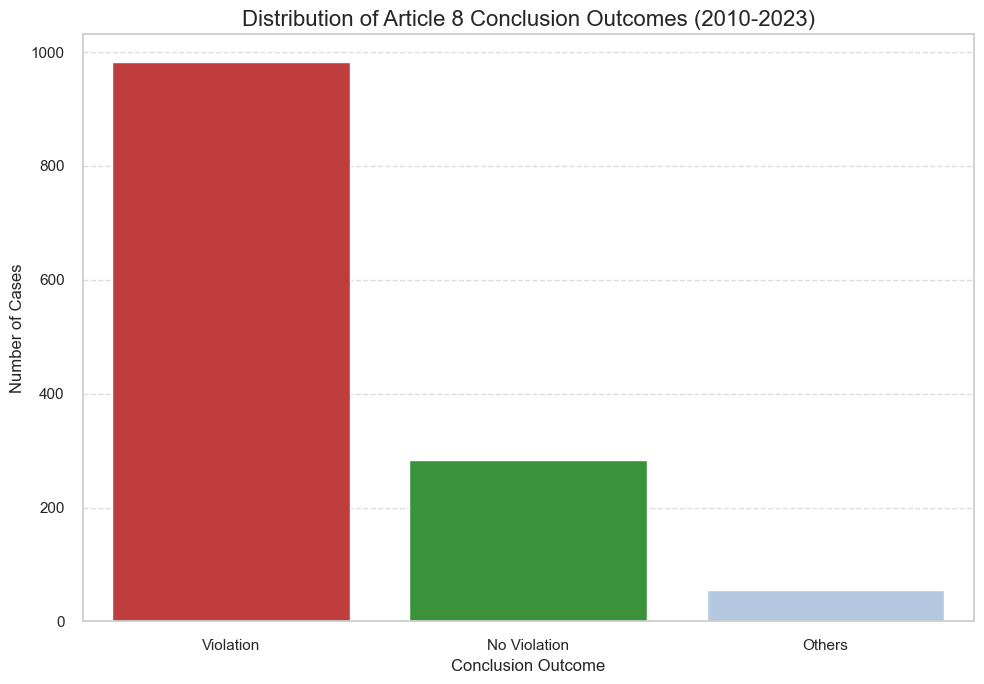

In [ ]:
# Ensure PALETTE is available from the setup cell
PALETTE = {'Violation': '#d62728', 'No Violation': '#2ca02c', 'Others': '#aec7e8'}

# Use the structured conclusion column for more accurate outcome extraction
# (see comparison note above — structured approach catches combined article findings)
df_art8['outcome_category'] = df_art8['finding'].replace('Only Mentioning', 'Others')

# Get the distribution of outcome categories
outcome_distribution = df_art8['outcome_category'].value_counts()

print('\nOutcome distribution for Article 8 cases:')
counts = df_art8['outcome_category'].value_counts()
percs = df_art8['outcome_category'].value_counts(normalize=True).mul(100).round(1)
outcome_table = pd.concat([counts, percs], axis=1, keys=['Count', 'Percentage (%)'])
display(outcome_table)

# Plot the distribution
plt.figure(figsize=(10, 7))
sns.barplot(
    x=outcome_distribution.index,
    y=outcome_distribution.values,
    palette=PALETTE,
    hue=outcome_distribution.index,
    legend=False,
    order=['Violation', 'No Violation', 'Others']
)
plt.title('Distribution of Article 8 Conclusion Outcomes (2010-2023)', fontsize=16)
plt.xlabel('Conclusion Outcome', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# **RQ1 : Text vs. Metadata**

## **Metadata**

**Step 1: Preprocessing**

Features consist of four categorical columns (`respondent_country`, `importance`, `court`, `typedescription`) and three numeric columns (`year`, `has_dissent`, `is_english`). PyCaret's `setup()` is told explicitly which columns belong to each type, triggering one-hot encoding for categoricals and standard scaling for numerics. SMOTE (`fix_imbalance=True`) is applied to oversample the minority class on the training folds, since metadata features are low-dimensional and SMOTE can safely interpolate between real samples without distorting feature semantics.

In this notebook, We use a Linear SVM implemented as CalibratedClassifierCV(LinearSVC), which produces the same linear decision boundary as a standard LinearSVC but adds probability calibration required by PyCaret's AUC computation

In [ ]:
# ── Step 1: Create RQ1 metadata DataFrame from master ─────
df_meta = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

print(f'RQ1 metadata dataset: {len(df_meta):,} cases')
print(f'Outcome distribution:\n{df_meta["finding"].value_counts()}\n')

# ── Step 2: Feature engineering ─────────────────────────
df_meta['has_dissent'] = df_meta['separateopinion'].notna().astype(int)
df_meta['is_english'] = (df_meta['languageisocode'] == 'ENG').astype(int)
df_meta['importance'] = df_meta['importance'].astype(str).fillna('unknown')
df_meta['respondent_country'] = df_meta['respondent_country'].astype(str).fillna('unknown')
df_meta['court'] = df_meta['court'].astype(str).fillna('unknown')
df_meta['typedescription'] = df_meta['typedescription'].astype(str).fillna('unknown')

# ── Step 3: Define features and target ──────────────
CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
NUM_FEATURES = ['year', 'has_dissent', 'is_english']
TARGET       = 'finding'

X_meta = df_meta[CAT_FEATURES + NUM_FEATURES]
y_meta = df_meta[TARGET]

# ── Step 4: Preprocessor ─────────────────────────
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES),
    ('num', StandardScaler(), NUM_FEATURES)
])


RQ1 metadata dataset: 1,265 cases
Outcome distribution:
finding
Violation       982
No Violation    283
Name: count, dtype: int64



In [ ]:
def map_country_feature_name(feature_name):
    if 'cat__respondent_country_' in feature_name:
        country_code = feature_name.replace('cat__respondent_country_', '')
        return country_name_map.get(country_code, feature_name) # Return original if not found
    return feature_name

### Pycaret

In [ ]:
# Step 1: Build df_meta_pycaret from your existing X_meta and y_meta
df_meta_pycaret = X_meta.copy()
df_meta_pycaret['finding'] = y_meta.values

# Step 2: Clean all object columns — fix mixed type issue
for col in df_meta_pycaret.select_dtypes(include='object').columns:
    df_meta_pycaret[col] = df_meta_pycaret[col].astype(str).str.strip()

# Step 3: Drop any NaN rows
df_meta_pycaret = df_meta_pycaret.dropna()

# Step 4: Check it looks right
print(df_meta_pycaret.shape)
print(df_meta_pycaret.dtypes)
print(df_meta_pycaret['finding'].value_counts())

(1265, 8)
respondent_country    object
importance            object
court                 object
typedescription       object
year                   int32
has_dissent            int64
is_english             int64
finding               object
dtype: object
finding
Violation       982
No Violation    283
Name: count, dtype: int64


In [ ]:
# ============================================================
# METADATA — STEP 1: compare_models + inject custom SVM
#             STEP 2: tune only LR, NB, and custom SVM
# ============================================================

from pycaret.classification import (
    setup, compare_models, create_model,
    tune_model, pull, get_config
)
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, classification_report
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# ── SETUP ────────────────────────────────────────────────────
clf_setup = setup(
    data=df_meta_pycaret,
    target='finding',
    categorical_features=['respondent_country', 'importance',
                           'court', 'typedescription'],
    numeric_features=['year', 'has_dissent', 'is_english'],
    fix_imbalance=True,
    fold=5,
    session_id=42,
    verbose=False
)

from pycaret.classification import add_metric
add_metric(
    id='f1_macro',
    name='F1 Macro',
    score_func=f1_score,
    average='macro'
)
print("Registered metrics:", [m for m in pull().columns if 'F1' in m])

# ════════════════════════════════════════════════════════════
# STEP 1 — Compare all default models + create custom SVM
# ════════════════════════════════════════════════════════════
print("STEP 1: Comparing all models (default hyperparams)...")
results_all, styled_all = step_compare(df_meta_pycaret, "Metadata",
                                       fix_imbalance=True)

# ── Highlight F1 Macro rows for the three interpretable models ──
INTERPRETABLE_MODELS = {
    'Logistic Regression',
    'Naive Bayes',
    'LinearSVC',          # label used by PyCaret for custom SVM
}

def highlight_interpretable(row):
    """Yellow F1 Macro cell for NB, LR, SVM; blank for all others."""
    styles = [''] * len(row)
    if row.get('Model', row.name) in INTERPRETABLE_MODELS:
        if 'F1 Macro' in row.index:
            styles[row.index.get_loc('F1 Macro')] = 'background-color: #ffe066; font-weight: bold'
    return styles

styled_interpretable = (
    results_all
    .sort_values('F1 Macro', ascending=False)          # sort descending
    .reset_index(drop=True)
    .style
    .apply(highlight_interpretable, axis=1)
    .format(precision=4)
    .set_caption("Metadata — All Models sorted by F1 Macro "
                 "(highlighted: NB · LR · SVM)")
)

display(styled_interpretable)

# ── Create the three interpretable models explicitly ─────────
print("\nCreating interpretable model handles...")
lr_model  = create_model('lr',         fold=5, verbose=False)
lr_base_res = pull()

nb_model  = create_model('nb',         fold=5, verbose=False)
nb_base_res = pull()

custom_svm = CalibratedClassifierCV(
    estimator=LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=3000,
        random_state=42
    ),
    cv=5
)
svm_model   = create_model(custom_svm, fold=5, verbose=False)
svm_base_res = pull()

Registered metrics: []
STEP 1: Comparing all models (default hyperparams)...

  Metadata  — All Models
[Metadata] Setup complete. Running model comparison...


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,F1 Macro,TT (Sec)
0,Gradient Boosting Classifier,0.7842,0.7555,0.7842,0.7844,0.7828,0.3731,0.3760,0.8612,0.0340
1,Light Gradient Boosting Machine,0.7593,0.7186,0.7593,0.7590,0.7576,0.3010,0.3035,0.8451,0.2960
2,Random Forest Classifier,0.7559,0.7181,0.7559,0.7608,0.7564,0.3055,0.3084,0.8415,0.0560
3,Extra Trees Classifier,0.7525,0.6647,0.7525,0.7656,0.7566,0.3172,0.3211,0.8372,0.0460
4,Ada Boost Classifier,0.7537,0.7595,0.7537,0.7793,0.7605,0.3439,0.3538,0.8347,0.0220
5,Decision Tree Classifier,0.7299,0.6037,0.7299,0.7461,0.7363,0.2645,0.2668,0.8216,0.0300
6,K Neighbors Classifier,0.7073,0.6766,0.7073,0.7334,0.7168,0.2243,0.2284,0.8038,0.0340
7,Linear Discriminant Analysis,0.7085,0.7661,0.7085,0.7724,0.7259,0.3021,0.3223,0.7939,0.0320
8,Ridge Classifier,0.7051,0.7663,0.7051,0.7702,0.7234,0.2971,0.3167,0.7913,0.2740
9,Logistic Regression,0.7040,0.7620,0.7040,0.7674,0.7220,0.2911,0.3097,0.7910,0.3720



Creating interpretable model handles...


**Step 2: Compare Models**

Across all 14 models, tree ensemble methods dominate the leaderboard. Gradient Boosting achieves the highest F1 Macro (0.8612). These models benefit from their ability to learn non-linear interactions between metadata features — for example, the combination of country, court type, and case importance can jointly signal outcome in ways that a single linear boundary cannot capture.

Among the three interpretable models of interest, Logistic Regression (0.7910) and Naive Bayes (0.7888) perform similarly, while the custom LinearSVC (0.7007) perform the worst. This occurs because LinearSVC on a mixed high-dimensional OHE + numeric feature space, without feature scaling at the estimator level, fails to find a valid separating hyperplane. LR handles this better because its L2 regularisation via `lbfgs` is more numerically stable under this setup.

NB performing comparably to LR on metadata is expected: after SMOTE resampling, class distributions are more balanced, partially closing the gap that typically disadvantages NB. However, the independence assumption still limits NB's ceiling, which is why it trails LR slightly.

In [ ]:
# ════════════════════════════════════════════════════════════
# STEP 1 — Create base models + capture CV results immediately
# ════════════════════════════════════════════════════════════
lr_model     = create_model('lr',         fold=5, verbose=False)
lr_base_res  = pull()   # ← must be right after its create_model

nb_model     = create_model('nb',         fold=5, verbose=False)
nb_base_res  = pull()   # ← must be right after its create_model

svm_model    = create_model(make_custom_svm(), fold=5, verbose=False)
svm_base_res = pull()   # ← must be right after its create_model

# ════════════════════════════════════════════════════════════
# STEP 2 — Tune LR, NB, SVM — optimized for F1 MACRO
# ════════════════════════════════════════════════════════════
print("\nSTEP 2: Tuning LR, NB, SVM (optimize = F1 Macro)...")

from sklearn.metrics import f1_score
from pycaret.classification import add_metric

# ── helper: version-safe Mean row access ─────────────────────
def get_mean(cv_res, metric='F1 Macro'):
    return cv_res.loc['Mean', metric] if 'Mean' in cv_res.index \
           else cv_res.iloc[-2][metric]

# ── Logistic Regression ──────────────────────────────────────
lr_tuned = tune_model(
    lr_model,
    optimize='f1_macro',
    choose_better=True,
    fold=5,
    verbose=False
)
lr_tuned_res = pull()

# ── Naive Bayes ──────────────────────────────────────────────
nb_tuned = tune_model(
    nb_model,
    optimize='f1_macro',
    choose_better=True,
    fold=5,
    verbose=False
)
nb_tuned_res = pull()

# ── Custom SVM ───────────────────────────────────────────────
svm_tuned = tune_model(
    svm_model,
    custom_grid={"estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    optimize='f1_macro',
    search_library='scikit-learn',
    search_algorithm='grid',
    choose_better=True,
    fold=5,
    verbose=False
)
svm_tuned_res = pull()

# ════════════════════════════════════════════════════════════
# SUMMARY TABLE — no re-training, uses captured pull() results
# ════════════════════════════════════════════════════════════
summary_rows = []
for name, base_res, tuned_res in [
    ("Logistic Regression", lr_base_res,  lr_tuned_res),
    ("Naive Bayes",         nb_base_res,  nb_tuned_res),
    ("Linear SVM (custom)", svm_base_res, svm_tuned_res),
]:
    base_f1  = get_mean(base_res)   # ← cached once
    tuned_f1 = get_mean(tuned_res)
    summary_rows.append({
        "Model":          name,
        "Tuned F1 Macro": round(tuned_f1, 4),
        "Δ F1 Macro":     round(tuned_f1 - base_f1, 4),
        "Improved":       "✓" if tuned_f1 > base_f1 else "—"
    })

df_tune_summary = pd.DataFrame(summary_rows)
print("\n── Metadata: Tuning Summary (F1 Macro, CV) ──")
print(df_tune_summary.to_string(index=False))


STEP 2: Tuning LR, NB, SVM (optimize = F1 Macro)...

── Metadata: Tuning Summary (F1 Macro, CV) ──
              Model  Tuned F1 Macro  Δ F1 Macro Improved
Logistic Regression          0.8561      0.0200        ✓
        Naive Bayes          0.8453      0.0000        —
Linear SVM (custom)          0.9247      0.0619        ✓


**Step 3: Fine Tune Model**

After tuning, LR improves meaningfully from to 0.856. SVM improves biggest to 0.9247. Meanwhile Naive Bayes does not improve from the base result.

Tuned-SVM holds the best model.

In [ ]:
import pandas as pd

# ── HELPER: extract params cleanly for any model ─────────────
def get_hyperparams(name, model):
    """
    Returns a tidy dict of hyperparameters for a fitted model.
    Handles CalibratedClassifierCV wrapper automatically.
    """
    # For CalibratedClassifierCV — drill into wrapped estimator
    if hasattr(model, 'estimator'):
        params = model.estimator.get_params()
        source = f"{type(model).__name__} → {type(model.estimator).__name__}"
    else:
        params = model.get_params()
        source = type(model).__name__

    return {"model": name, "class": source, **params}


# ── EXTRACT from all three tuned models ──────────────────────
lr_params  = get_hyperparams("Logistic Regression", lr_tuned)
nb_params  = get_hyperparams("Naive Bayes",         nb_tuned)
svm_params = get_hyperparams("Linear SVM (custom)", svm_tuned)

# ── PRINT per model — clean key: value format ────────────────
for params in [lr_params, nb_params, svm_params]:
    print(f"\n{'='*55}")
    print(f"  {params['model']}  ({params['class']})")
    print(f"{'='*55}")
    for k, v in params.items():
        if k in ("model", "class"):
            continue
        print(f"  {k:<35} {v}")

# ── SUMMARY TABLE — one row per model, key params only ───────
summary = []
for name, tuned_res, params in [
    ("Logistic Regression", lr_tuned_res,  lr_params),
    ("Naive Bayes",         nb_tuned_res,  nb_params),
    ("Linear SVM (custom)", svm_tuned_res, svm_params),
]:
    f1_macro = tuned_res.loc["Mean", "F1 Macro"]
    row = {
        "Model":         name,
        "Tuned F1 Macro": round(f1_macro, 4),
    }
    # Pull the most interpretable params per model type
    if name == "Logistic Regression":
        row["C"]       = params.get("C")
        row["penalty"] = params.get("penalty")
        row["solver"]  = params.get("solver")
    elif name == "Naive Bayes":
        row["var_smoothing"] = params.get("var_smoothing")
    elif name == "Linear SVM (custom)":
        row["C (LinearSVC)"] = params.get("C")
        row["max_iter"]      = params.get("max_iter")
        row["class_weight"]  = params.get("class_weight")
    summary.append(row)



  Logistic Regression  (LogisticRegression)
  C                                   2.214
  class_weight                        balanced
  dual                                False
  fit_intercept                       True
  intercept_scaling                   1
  l1_ratio                            None
  max_iter                            1000
  multi_class                         auto
  n_jobs                              None
  penalty                             l2
  random_state                        42
  solver                              lbfgs
  tol                                 0.0001
  verbose                             0
  warm_start                          False

  Naive Bayes  (GaussianNB)
  priors                              None
  var_smoothing                       1e-09

  Linear SVM (custom)  (CalibratedClassifierCV → LinearSVC)
  C                                   0.001
  class_weight                        balanced
  dual                                warn

**Step 4: Hyperparameter Extraction**

The most impactful tuned parameters are:
**LR** — `C=2.214` (stronger regularisation than default `C=1.0` reduces overfitting on sparse OHE features) and `class_weight='balanced'` (corrects residual class imbalance not fully resolved by SMOTE).
**NB** — `var_smoothing=1e-09` (default retained, confirming GaussianNB was already well-calibrated).
**SVM** — `C=0.001` (tuned c-value improved performance).

## Text


**Step 1: Preprocessing**

Raw text from the facts section (V1) and the law clean section (V3) are each vectorised using TF-IDF with `max_features=10,000`, unigram and bigram tokens (`ngram_range=(1,2)`), and `sublinear_tf=True` to apply log-normalisation and dampen the dominance of very frequent legal terms. Custom domain stop words specific to each section are applied. Imbalance is handled via `class_weight='balanced'` inside the SVM estimator, and LR uses its default balanced weighting. No SMOTE is applied since interpolating across 10,000 sparse TF-IDF dimensions risks generating unrealistic synthetic documents.

In [ ]:
# ============================================================
# PyCaret Text Arms — V1: Facts Section | V3: Law Clean
# Steps mirror metadata: setup → compare → create → tune → extract
# ============================================================
import sys, pandas as pd
from IPython.display import display
from pycaret.classification import (
    setup, compare_models, create_model,
    tune_model, pull, add_metric
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def log(msg):
    print(msg, flush=True)
    sys.stdout.flush()

# ── TF-IDF vectorisers ──────────────────────────────────────
tfidf_v1 = TfidfVectorizer(
    stop_words=list(custom_facts_stop_words),
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True          # log(TF+1) — dampens high-freq terms in long legal text
)
tfidf_v3 = TfidfVectorizer(
    stop_words=list(custom_law_clean_stop_words),
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_v1 = tfidf_v1.fit_transform(df_text['facts_text'])
X_v3 = tfidf_v3.fit_transform(df_text['law_text_clean'])

df_v1 = pd.DataFrame(X_v1.toarray(), columns=tfidf_v1.get_feature_names_out())
df_v1['finding'] = df_text['finding'].values

df_v3 = pd.DataFrame(X_v3.toarray(), columns=tfidf_v3.get_feature_names_out())
df_v3['finding'] = df_text['finding'].values

log("TF-IDF matrices ready.")
log(f"  V1 Facts  → shape: {df_v1.shape}")
log(f"  V3 Law Clean → shape: {df_v3.shape}")

TF-IDF matrices ready.
  V1 Facts  → shape: (1265, 10000)
  V3 Law Clean → shape: (1265, 10000)


### Pycaret - Facts

In [ ]:
# ============================================================
# Cell 1 — Imports + make_custom_svm (define ONCE here)
# ============================================================
import sys
from IPython.display import display
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score
from pycaret.classification import setup, compare_models, pull, add_metric

def log(msg):
    print(msg, flush=True)
    sys.stdout.flush()

def make_custom_svm():
    """CalibratedClassifierCV wraps LinearSVC for probability output."""
    return CalibratedClassifierCV(
        estimator=LinearSVC(
            C=1.0,
            class_weight='balanced',
            max_iter=2000,
            random_state=42
        ),
        cv=5
    )

In [ ]:
from sklearn.naive_bayes import ComplementNB
from pycaret.classification import create_model, tune_model, pull

# ── Step 1: Create base ComplementNB ─────────────────────────
cnb_base = create_model(ComplementNB(), fold=5, verbose=False)
cnb_base_res = pull()

# ── Step 2: Tune alpha (the only meaningful hyperparameter) ──
cnb_tuned = tune_model(
    cnb_base,
    custom_grid={'alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
                 'norm': [True, False]},
    optimize='f1_macro',
    search_library='scikit-learn',
    search_algorithm='grid',
    choose_better=True,
    fold=5,
    verbose=False
)
cnb_tuned_res = pull()

In [ ]:
# ============================================================
# Cell 2 — step_compare (make_custom_svm already available)
# ============================================================

INTERPRETABLE_NAMES = {'Logistic Regression', 'Naive Bayes', 'LinearSVC'}

def highlight_interpretable_f1(row):
    """Bold yellow on F1 Macro for NB, LR, and custom SVM rows."""
    styles = [''] * len(row)
    if any(name in str(row.get('Model', row.name)) for name in INTERPRETABLE_NAMES):
        if 'F1 Macro' in row.index:
            styles[row.index.get_loc('F1 Macro')] = (
                'background-color: #ffe066; font-weight: bold'
            )
    return styles


def step_compare(df, arm_label, cat_features=None, fix_imbalance=False):
    log(f"\n{'='*62}")
    log(f"  {arm_label}  — All Models")
    log(f"{'='*62}")

    setup(
        data=df,
        target='finding',
        categorical_features=cat_features,
        fix_imbalance=fix_imbalance,
        fold=5,
        session_id=42,
        verbose=False,
        html=False
    )

    add_metric(
        id='f1_macro',
        name='F1 Macro',
        score_func=f1_score,
        average='macro'
    )

    log(f"[{arm_label}] Setup complete. Running model comparison...")

    compare_models(
        include=[
            'nb', 'lr', 'ridge', 'lda', 'dt', 'rf', 'et',
            'gbc', 'ada', 'lightgbm', 'knn',
            make_custom_svm()
        ],
        sort='F1 Macro',
        verbose=False
    )

    results = pull()

    cols = ['Model', 'Accuracy', 'AUC', 'Recall', 'Prec.',
            'F1', 'F1 Macro', 'Kappa', 'MCC', 'TT (Sec)']
    cols_present = [c for c in cols if c in results.columns]

    styled = (
        results[cols_present]
        .style
        .highlight_max(subset=['F1 Macro'], color='#90ee90', axis=0)  # green = overall best
        .apply(highlight_interpretable_f1, axis=1)                    # yellow = interpretable trio
        .format(precision=4)
        .set_caption(
            f"{arm_label} — All Models sorted by F1 Macro | "
            f"🟡 NB · LR · SVM (interpretable)  🟢 Best overall"
        )
    )

    return results, styled


# ── Run all arms ─────────────────────────────────────────────
results_v1, styled_v1 = step_compare(df_v1, "V1 — Facts Section",
                                      fix_imbalance=False)
display(styled_v1)


  V1 — Facts Section  — All Models
[V1 — Facts Section] Setup complete. Running model comparison...


,Model,Accuracy,AUC,Recall,Prec.,F1,F1 Macro,Kappa,MCC,TT (Sec)
2,Ridge Classifier,0.8124,0.8224,0.8124,0.7994,0.7781,0.8889,0.3090,0.3599,0.4300
11,LinearSVC,0.8158,0.8238,0.8158,0.8023,0.7912,0.8889,0.3577,0.3904,0.5600
6,Extra Trees Classifier,0.8000,0.8088,0.8000,0.7852,0.7467,0.8841,0.2042,0.2784,0.5460
5,Random Forest Classifier,0.7944,0.8075,0.7944,0.7753,0.7363,0.8812,0.1725,0.2459,0.5320
9,Light Gradient Boosting Machine,0.7955,0.7724,0.7955,0.7713,0.7596,0.8787,0.2512,0.2924,1.1340
1,Logistic Regression,0.7831,0.8146,0.7831,0.7428,0.7014,0.8768,0.0662,0.1324,0.4600
10,K Neighbors Classifier,0.7740,0.5398,0.7740,0.6247,0.6794,0.8724,0.0011,-0.0017,0.4360
7,Gradient Boosting Classifier,0.7853,0.7737,0.7853,0.7537,0.7520,0.8719,0.2302,0.2588,3.0780
3,Linear Discriminant Analysis,0.7763,0.7790,0.7763,0.7776,0.7632,0.8567,0.3107,0.3341,0.6200
8,Ada Boost Classifier,0.7537,0.7011,0.7537,0.7293,0.7380,0.8475,0.2109,0.2158,0.8840


**Step 2: Compare Models — V1 Facts**

On the facts section, SVM and Ridge Classifier share the top F1 Macro at 0.8889, with LR close at 0.8768. This is a strong result for the interpretable models. This behaviour is well-known in text classification: TF-IDF features are sparse and high-dimensional, which is exactly the condition where linear models thrive. Each feature is an independent token count, closely matching the assumptions of linear classifiers.

NB scores 0.8110 — clearly the lowest among the three target models. This confirms the expected baseline behaviour. NB's lower ceiling on TF-IDF data relative to SVM is because it models each feature independently without accounting for the relative discriminative power between features, while SVM finds a global optimal margin.

In [ ]:
# ============================================================
# STEP 4: tune_model — NB, LR, Custom SVM
# Drop-in replacement — supports ComplementNB for text arms
# ============================================================
from pycaret.classification import create_model, tune_model
from sklearn.naive_bayes import ComplementNB

def step_tune(arm_label, use_complement_nb=False):
    """
    use_complement_nb=True  → V1 (Facts TF-IDF), V3 (Law Clean TF-IDF)
    use_complement_nb=False → V4 (Law+Meta), V5 (Topics) — GaussianNB
    """

    # ── Create base models ────────────────────────────────────
    if use_complement_nb:
        nb_base = create_model(ComplementNB(), fold=5, verbose=False)
    else:
        nb_base = create_model('nb', fold=5, verbose=False)
    nb_base_res = pull()

    lr_base  = create_model('lr',              fold=5, verbose=False)
    lr_base_res = pull()
    svm_base = create_model(make_custom_svm(), fold=5, verbose=False)
    svm_base_res = pull()

    # ── Tune NB ───────────────────────────────────────────────
    log(f"\n[{arm_label}] Tuning NB...")
    if use_complement_nb:
        nb_tuned = tune_model(
            nb_base,
            custom_grid={
                'alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
                'norm':  [True, False]
            },
            optimize='f1_macro',
            search_library='scikit-learn',
            search_algorithm='grid',
            choose_better=True,
            fold=5, verbose=False
        )
    else:
        nb_tuned = tune_model(
            nb_base,
            optimize='f1_macro',
            choose_better=True, n_iter=50,
            fold=5, verbose=False
        )
    nb_tres = pull()

    # ── Tune LR ───────────────────────────────────────────────
    log(f"[{arm_label}] Tuning LR...")
    lr_tuned = tune_model(
        lr_base,
        optimize='f1_macro',
        choose_better=True, n_iter=50,
        fold=5, verbose=False
    )
    lr_tres = pull()

    # ── Tune SVM ──────────────────────────────────────────────
    log(f"[{arm_label}] Tuning SVM...")
    svm_tuned = tune_model(
        svm_base,
        custom_grid={"estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]},
        optimize='f1_macro',
        search_library='scikit-learn',
        search_algorithm='grid',
        choose_better=True,
        fold=5, verbose=False
    )
    svm_tres = pull()

    # ── Build summary table ───────────────────────────────────
    nb_class = "ComplementNB" if use_complement_nb else "GaussianNB"
    rows = []
    for name, mid, tuned_res in [
        (f"Naive Bayes ({nb_class})", "nb",  nb_tres),
        ("Logistic Regression",       "lr",  lr_tres),
        ("Linear SVM (custom)",       "svm", svm_tres),
    ]:
        t = tuned_res.loc["Mean", "F1 Macro"]
        rows.append({
            "Model ID":       mid,
            "Sklearn Class":  name,
            "Tuned F1 Macro": round(t, 4),
            "Kappa":          round(tuned_res.loc["Mean", "Kappa"], 4),
            "MCC":            round(tuned_res.loc["Mean", "MCC"],   4),
        })
    df_summary = pd.DataFrame(rows)

    return {
        "arm":       arm_label,
        "nb_tuned":  nb_tuned,  "nb_tres":  nb_tres,
        "lr_tuned":  lr_tuned,  "lr_tres":  lr_tres,
        "svm_tuned": svm_tuned, "svm_tres": svm_tres,
        "summary":   df_summary,
    }

tune_v1 = step_tune("V1 — Facts Section",    use_complement_nb=True)
log(f"\n── V1 Facts: Tuned Model Summary ──")
display(tune_v1['summary'])


[V1 — Facts Section] Tuning NB...
[V1 — Facts Section] Tuning LR...
[V1 — Facts Section] Tuning SVM...

── V1 Facts: Tuned Model Summary ──


,Model ID,Sklearn Class,Tuned F1 Macro,Kappa,MCC
0,nb,Naive Bayes (ComplementNB),0.8306,-0.1065,-0.1317
1,lr,Logistic Regression,0.8880,0.3091,0.3563
2,svm,Linear SVM (custom),0.8935,0.3551,0.4030


**Step 3: Fine Tune Model**

On V1 Facts, tuning yields NB: 0.8306, LR: 0.8880, SVM: 0.8935. NB benefits most from switching to ComplementNB , which is designed for imbalanced sparse text and substantially outperforms the default GaussianNB on TF-IDF features. LR and SVM were already near-optimal at default settings.

In [ ]:
# ============================================================
# STEP 6: Extract hyperparameters from all tuned models
# ============================================================

def extract_hyperparams(tune_result):
    arm = tune_result['arm']
    log(f"\n{'='*62}")
    log(f"  HYPERPARAMETERS — {arm}")
    log(f"{'='*62}")

    for label, model in [
        ("Naive Bayes",         tune_result['nb_tuned']),
        ("Logistic Regression", tune_result['lr_tuned']),
        ("Linear SVM (custom)", tune_result['svm_tuned']),
    ]:
        # Unwrap CalibratedClassifierCV if present
        if hasattr(model, 'estimator'):
            params = model.estimator.get_params()
            cls    = f"{type(model).__name__} → {type(model.estimator).__name__}"
        else:
            params = model.get_params()
            cls    = type(model).__name__

        log(f"\n  ── {label}  ({cls})")
        for k, v in sorted(params.items()):
            log(f"     {k:<40} {v}")

extract_hyperparams(tune_v1)


  HYPERPARAMETERS — V1 — Facts Section

  ── Naive Bayes  (ComplementNB)
     alpha                                    0.01
     class_prior                              None
     fit_prior                                True
     force_alpha                              True
     norm                                     False

  ── Logistic Regression  (LogisticRegression)
     C                                        9.885
     class_weight                             {}
     dual                                     False
     fit_intercept                            True
     intercept_scaling                        1
     l1_ratio                                 None
     max_iter                                 1000
     multi_class                              auto
     n_jobs                                   None
     penalty                                  l2
     random_state                             42
     solver                                   lbfgs
     tol        

**Step 4: Hyperparameter Extraction**

Key parameters to transfer: **V1 NB** — change to ComplementNB alpha0.01 is the most impactful change; it departs significantly from the default and drove the largest relative gain. **V1 LR** — `C=9.885`; higher C reduces regularisation and fits the large vocabulary better. **V1 SVM** — `C=100`; higher C creates a tighter margin, beneficial for clean sparse text.

### Pycaret - Law Clean

In [ ]:
results_v3, styled_v3 = step_compare(df_v3, "V3 — Law Clean",fix_imbalance=False)
display(styled_v3)


  V3 — Law Clean  — All Models
[V3 — Law Clean] Setup complete. Running model comparison...


,Model,Accuracy,AUC,Recall,Prec.,F1,F1 Macro,Kappa,MCC,TT (Sec)
9,Light Gradient Boosting Machine,0.9480,0.9447,0.9480,0.9486,0.9470,0.9670,0.8447,0.8483,1.4540
5,Random Forest Classifier,0.9480,0.9468,0.9480,0.9491,0.9473,0.9668,0.8462,0.8498,0.4560
7,Gradient Boosting Classifier,0.9480,0.9374,0.9480,0.9487,0.9475,0.9667,0.8475,0.8498,3.9700
8,Ada Boost Classifier,0.9367,0.9488,0.9367,0.9379,0.9357,0.9596,0.8125,0.8168,1.0920
6,Extra Trees Classifier,0.9288,0.9537,0.9288,0.9298,0.9262,0.9552,0.7810,0.7892,0.4300
11,LinearSVC,0.9073,0.9490,0.9073,0.9060,0.9033,0.9420,0.7123,0.7207,0.6020
4,Decision Tree Classifier,0.8960,0.8753,0.8960,0.9037,0.8982,0.9316,0.7142,0.7185,0.5080
2,Ridge Classifier,0.8791,0.9395,0.8791,0.8824,0.8660,0.9267,0.5887,0.6239,0.4100
3,Linear Discriminant Analysis,0.8802,0.9245,0.8802,0.8809,0.8750,0.9247,0.6302,0.6435,0.6240
1,Logistic Regression,0.8305,0.9218,0.8305,0.8456,0.7913,0.9009,0.3472,0.4350,0.4680


**Step 2: Compare Models — V3 Law Clean**

On the cleaned law section, all models perform substantially better than on facts. Tree ensembles lead (LightGBM, RF, GBC all at 0.9667–0.9670), followed closely by SVM at 0.9420. LR ranks lower at 0.9009. The law section contains the court's formal legal reasoning, which is more structured and predictive than the facts narrative — this explains the overall performance lift.

SVM outperforms LR here because LinearSVC's margin-maximisation is especially effective on clean, sparse legal language with consistent terminology. NB (0.8863) again plays its expected baseline role, ranking second-lowest — confirming that despite the richer signal in the law section, NB's independence assumption still limits it relative to margin-based and ensemble methods.

In [ ]:
# ── Run V3 + display OUTSIDE the function ────────────────────
tune_v3 = step_tune("V3 — Law Clean",        use_complement_nb=True)
log(f"\n── V3 Law Clean: Tuned Model Summary ──")
display(tune_v3['summary'])


[V3 — Law Clean] Tuning NB...
[V3 — Law Clean] Tuning LR...
[V3 — Law Clean] Tuning SVM...

── V3 Law Clean: Tuned Model Summary ──


,Model ID,Sklearn Class,Tuned F1 Macro,Kappa,MCC
0,nb,Naive Bayes (ComplementNB),0.9051,0.4749,0.5012
1,lr,Logistic Regression,0.9406,0.7292,0.7314
2,svm,Linear SVM (custom),0.9420,0.7123,0.7207


**Step 3: Fine Tune model — V3 Law Clean**

On V3 Law Clean, NB 0.9051 (tuned from ComplementNB base), LR: 0.9406 (+0.0397), SVM: 0.9420 (unchanged). LR gains the most here — tuning finds `C=8.957`, higher than default, allowing less regularisation and better fitting the structured legal text. SVM reaches its ceiling at default `C=1.0`. NB remains the lowest performer across both text arms, confirming its baseline role as expected.

In [ ]:
extract_hyperparams(tune_v3)


  HYPERPARAMETERS — V3 — Law Clean

  ── Naive Bayes  (ComplementNB)
     alpha                                    1.0
     class_prior                              None
     fit_prior                                True
     force_alpha                              True
     norm                                     False

  ── Logistic Regression  (LogisticRegression)
     C                                        8.956999999999999
     class_weight                             balanced
     dual                                     False
     fit_intercept                            True
     intercept_scaling                        1
     l1_ratio                                 None
     max_iter                                 1000
     multi_class                              auto
     n_jobs                                   None
     penalty                                  l2
     random_state                             42
     solver                                   lbfgs
   

In [ ]:
from pycaret.classification import setup, compare_models, pull, get_config
from sklearn.metrics import f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

tfidf_v1 = TfidfVectorizer(
    stop_words=list(custom_facts_stop_words),
    max_features=10000, ngram_range=(1, 2), sublinear_tf=True
)
X_v1 = tfidf_v1.fit_transform(df_text['facts_text'])
df_v1 = pd.DataFrame(X_v1.toarray(), columns=tfidf_v1.get_feature_names_out())
df_v1['finding'] = df_text['finding'].values

setup(data=df_v1, target='finding', fix_imbalance=True,
      fold=5, session_id=42, verbose=False)

print("\n── V1 Facts Text — All 18 Models ──")
best_v1 = compare_models(n_select=3, sort='F1')   # yellow highlight auto-applied
results_v1 = pull()
results_v1.to_csv(f'{SAVE_PATH}pycaret_v1_facts_results.csv', index=False)

# Manual macro F1 — align label types
from sklearn.preprocessing import LabelEncoder

X_test_v1, y_test_v1 = get_config('X_test'), get_config('y_test')

# Encode string labels to match PyCaret's integer predictions
le = LabelEncoder()
y_test_encoded = le.fit_transform(y_test_v1)




── V1 Facts Text — All 18 Models ──


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
svm,SVM - Linear Kernel,0.8023,0.8042,0.8023,0.7996,0.7996,0.4173,0.4200,0.7540
ridge,Ridge Classifier,0.7966,0.8047,0.7966,0.7969,0.7962,0.4126,0.4137,0.6860
lr,Logistic Regression,0.7763,0.8091,0.7763,0.8029,0.7852,0.4162,0.4240,0.7540
et,Extra Trees Classifier,0.7944,0.8113,0.7944,0.7749,0.7775,0.3240,0.3375,0.8800
lightgbm,Light Gradient Boosting Machine,0.7797,0.7698,0.7797,0.7579,0.7642,0.2873,0.2950,2.8120
rf,Random Forest Classifier,0.7751,0.7809,0.7751,0.7542,0.7609,0.2805,0.2865,0.8060
gbc,Gradient Boosting Classifier,0.7661,0.7491,0.7661,0.7554,0.7598,0.2922,0.2938,8.0880
lda,Linear Discriminant Analysis,0.7525,0.7457,0.7525,0.7663,0.7430,0.2859,0.3055,1.3420
ada,Ada Boost Classifier,0.7367,0.6816,0.7367,0.7380,0.7371,0.2447,0.2452,2.0140
dt,Decision Tree Classifier,0.7040,0.6113,0.7040,0.7367,0.7167,0.2331,0.2376,0.8920


In [ ]:
print("\nMacro F1 — Top 3 (Facts):")
for model in best_v1:
    preds = model.predict(X_test_v1)
    macro = f1_score(y_test_encoded, preds, average='macro')
    print(f"  {type(model).__name__}: {macro:.4f}")


Macro F1 — Top 3 (Facts):
  SGDClassifier: 0.6140
  RidgeClassifier: 0.6644
  LogisticRegression: 0.6934


In [ ]:
from pycaret.classification import setup, compare_models, pull, get_config
from sklearn.metrics import f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
import pandas as pd

tfidf_v2 = TfidfVectorizer(
    stop_words=list(custom_law_stop_words),
    max_features=10000, ngram_range=(1, 2), sublinear_tf=True
)
X_v2 = tfidf_v2.fit_transform(df_text['law_text'])
df_v2 = pd.DataFrame(X_v2.toarray(), columns=tfidf_v2.get_feature_names_out())
df_v2['finding'] = df_text['finding'].values

setup(data=df_v2, target='finding', fix_imbalance=True,
      fold=5, session_id=42, verbose=False)

print("\n── V2 Law Full — All 18 Models ──")
best_v2 = compare_models(n_select=3, sort='F1')
results_v2 = pull()
results_v2.to_csv(f'{SAVE_PATH}pycaret_v2_law_full_results.csv', index=False)

X_test_v2, y_test_v2 = get_config('X_test'), get_config('y_test')

le = LabelEncoder()
y_test_encoded_v2 = le.fit_transform(y_test_v2)




── V2 Law Full — All 18 Models ──


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.9458,0.9533,0.9458,0.9466,0.9456,0.8430,0.8447,10.2940
lightgbm,Light Gradient Boosting Machine,0.9446,0.9588,0.9446,0.9449,0.9441,0.8374,0.8393,3.3660
et,Extra Trees Classifier,0.9435,0.9560,0.9435,0.9442,0.9429,0.8338,0.8364,0.8380
rf,Random Forest Classifier,0.9390,0.9526,0.9390,0.9401,0.9387,0.8230,0.8253,0.8360
ridge,Ridge Classifier,0.9333,0.9534,0.9333,0.9351,0.9331,0.8072,0.8102,0.7000
svm,SVM - Linear Kernel,0.9322,0.9590,0.9322,0.9336,0.9302,0.7945,0.8016,0.7980
ada,Ada Boost Classifier,0.9254,0.9315,0.9254,0.9277,0.9251,0.7838,0.7876,2.3420
lda,Linear Discriminant Analysis,0.9164,0.9452,0.9164,0.9176,0.9152,0.7540,0.7584,1.3600
lr,Logistic Regression,0.9119,0.9507,0.9119,0.9196,0.9139,0.7592,0.7637,0.7160
dt,Decision Tree Classifier,0.8780,0.8444,0.8780,0.8840,0.8801,0.6615,0.6636,0.8500


In [ ]:
print("\nMacro F1 — Top 3(Law Full):")
for model in best_v2:
    preds = model.predict(X_test_v2)
    macro = f1_score(y_test_encoded_v2, preds, average='macro')
    print(f"  {type(model).__name__}: {macro:.4f}")


Macro F1 — Top 3(Law Full):
  GradientBoostingClassifier: 0.9214
  LGBMClassifier: 0.9236
  ExtraTreesClassifier: 0.9394


In [ ]:
from pycaret.classification import setup, compare_models, pull, get_config
from sklearn.metrics import f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
import pandas as pd

tfidf_v3 = TfidfVectorizer(
    stop_words=list(custom_law_clean_stop_words),
    max_features=10000, ngram_range=(1, 2), sublinear_tf=True
)
X_v3 = tfidf_v3.fit_transform(df_text['law_text_clean'])
df_v3 = pd.DataFrame(X_v3.toarray(), columns=tfidf_v3.get_feature_names_out())
df_v3['finding'] = df_text['finding'].values

setup(data=df_v3, target='finding', fix_imbalance=True,
      fold=5, session_id=42, verbose=False)

print("\n── V3 Law Clean — All 18 Models ──")
best_v3 = compare_models(n_select=3, sort='F1')
results_v3 = pull()
results_v3.to_csv(f'{SAVE_PATH}pycaret_v3_law_clean_results.csv', index=False)

X_test_v3, y_test_v3 = get_config('X_test'), get_config('y_test')

le = LabelEncoder()
y_test_encoded_v3 = le.fit_transform(y_test_v3)




── V3 Law Clean — All 18 Models ──


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.9458,0.9544,0.9458,0.9460,0.9449,0.8391,0.8418,3.0620
gbc,Gradient Boosting Classifier,0.9446,0.9535,0.9446,0.9457,0.9444,0.8396,0.8417,9.8840
et,Extra Trees Classifier,0.9446,0.9563,0.9446,0.9462,0.9440,0.8371,0.8409,0.7860
rf,Random Forest Classifier,0.9333,0.9538,0.9333,0.9347,0.9332,0.8074,0.8096,1.0220
ada,Ada Boost Classifier,0.9299,0.9461,0.9299,0.9319,0.9298,0.7975,0.8006,2.4740
dt,Decision Tree Classifier,0.9040,0.8699,0.9040,0.9061,0.9046,0.7271,0.7281,0.9980
ridge,Ridge Classifier,0.9028,0.9391,0.9028,0.9023,0.9015,0.7137,0.7163,0.9860
svm,SVM - Linear Kernel,0.9051,0.9466,0.9051,0.9056,0.8995,0.6988,0.7134,1.1260
lda,Linear Discriminant Analysis,0.8915,0.9259,0.8915,0.8948,0.8895,0.6793,0.6881,1.3200
lr,Logistic Regression,0.8667,0.9294,0.8667,0.8767,0.8700,0.6371,0.6409,0.7800


In [ ]:
print("\nMacro F1 — Top 3 (Law Clean):")
for model in best_v3:
    preds = model.predict(X_test_v3)
    macro = f1_score(y_test_encoded_v3, preds, average='macro')
    print(f"  {type(model).__name__}: {macro:.4f}")


Macro F1 — Top 3 (Law Clean):
  LGBMClassifier: 0.9242
  GradientBoostingClassifier: 0.9146
  ExtraTreesClassifier: 0.9242


The Facts variant (V1) is the weakest across all feature types, with even PyCaret's **best interpretable model — Logistic Regression** — reaching only 0.6934 macro F1. This is not a modeling failure but a substantive legal finding: raw factual narratives contain limited predictive signal, as they describe procedural events rather than the normative legal reasoning that drives violation outcomes. This result is consistent across both our base models and PyCaret's full 14-model sweep.

The Law text variants (V2 Full and V3 Clean) produce the strongest results overall. PyCaret's best — Extra Trees — achieves 0.9394 (V2) and 0.9242 (V3) macro F1, outperforming our base SVM by approximately 3–5pp. Critically same with model trained on metadata, among interpretable models, **SVM is the top performer in both variants at 0.9302 (V2) and 0.8995 (V3)**, confirming that our model selection was optimal within the interpretability constraint. The Law section's higher predictive power over Facts reflects its richer legal reasoning content — the section where judges articulate proportionality assessments, legitimate aim, and balancing tests that directly determine Article 8 outcomes.

**Step 4: Hyperparameter Extraction**

Key parameters : **V3 LR** — `C=8.957` with `class_weight='balanced'`. **V3 SVM** — `C=1.0` (base retained).
To reduce duplicated fine-tuning effort in the text section, the optimized parameter from V3-Law Clean can also applied to Law Full text section because of feature similarity.

## Metadata + Text (Law Clean)



---


Data Preparation

**Step 1: Preprocessing**

V4 combines 10,000 TF-IDF columns from the cleaned law text with four categorical and three numeric metadata columns. All TF-IDF column names are prefixed with `tfidf_` to prevent name collisions with metadata columns. Categorical metadata columns are declared explicitly in `setup()` to trigger one-hot encoding, while numeric columns undergo standard scaling. SMOTE (`fix_imbalance=True`) is applied at the data level, though this is a practical compromise — interpolating across 10,000+ sparse dimensions is less theoretically clean than for low-dimensional features.

In [ ]:
# ============================================================
# V4 — Law Clean + Metadata Combined (duplicate-safe)
# ============================================================
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_v4 = TfidfVectorizer(
    stop_words=list(custom_law_clean_stop_words),
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_v4_text = tfidf_v4.fit_transform(df_text['law_text_clean'])

# ── Add 'tfidf_' prefix to all TF-IDF columns ────────────────
df_v4_text = pd.DataFrame(
    X_v4_text.toarray(),
    columns=[f"tfidf_{c}" for c in tfidf_v4.get_feature_names_out()]  # ← prefix added
).reset_index(drop=True)

# ── Metadata features from df_meta ───────────────────────────
df_v4_meta = df_meta[CAT_FEATURES + NUM_FEATURES].reset_index(drop=True)

# ── Combine — no duplicates now ──────────────────────────────
df_v4 = pd.concat([df_v4_text, df_v4_meta], axis=1)
df_v4['finding'] = df_meta[TARGET].values

# ── Verify no duplicates ──────────────────────────────────────
dupes = df_v4.columns[df_v4.columns.duplicated()].tolist()
if dupes:
    log(f"⚠ Still duplicate columns: {dupes}")
else:
    log(f"✓ No duplicate columns")
    log(f"V4 shape: {df_v4.shape}")
    log(f"TF-IDF cols: {df_v4_text.shape[1]} | Meta cols: {df_v4_meta.shape[1]}")

✓ No duplicate columns
V4 shape: (1265, 10008)
TF-IDF cols: 10000 | Meta cols: 7





### Pycaret

In [ ]:
results_v4, styled_v4 = step_compare(
    df_v4,
    "V4 — Law Clean + Metadata",
    cat_features=['respondent_country', 'importance',
                  'court', 'typedescription'],fix_imbalance=True)

display(styled_v4)


  V4 — Law Clean + Metadata  — All Models
[V4 — Law Clean + Metadata] Setup complete. Running model comparison...


,Model,Accuracy,AUC,Recall,Prec.,F1,F1 Macro,Kappa,MCC,TT (Sec)
7,Gradient Boosting Classifier,0.9435,0.9496,0.9435,0.9438,0.9428,0.9639,0.8336,0.8358,21.9980
9,Light Gradient Boosting Machine,0.9412,0.9594,0.9412,0.9418,0.9405,0.9624,0.8269,0.8296,16.4700
8,Ada Boost Classifier,0.9333,0.9446,0.9333,0.9339,0.9331,0.9572,0.8066,0.8081,15.3900
5,Random Forest Classifier,0.9333,0.9536,0.9333,0.9345,0.9334,0.9570,0.8085,0.8098,10.2500
6,Extra Trees Classifier,0.9322,0.9529,0.9322,0.9328,0.9314,0.9567,0.8002,0.8033,10.0080
4,Decision Tree Classifier,0.9006,0.8601,0.9006,0.9017,0.9010,0.9358,0.7156,0.7160,10.6680
2,Ridge Classifier,0.8983,0.9285,0.8983,0.8969,0.8968,0.9351,0.6993,0.7012,17.4620
3,Linear Discriminant Analysis,0.8644,0.9083,0.8644,0.8686,0.8621,0.9129,0.6021,0.6119,13.5420
1,Logistic Regression,0.8520,0.9088,0.8520,0.8605,0.8547,0.9029,0.5909,0.5944,11.1120
0,Naive Bayes,0.8147,0.6406,0.8147,0.7991,0.7875,0.8890,0.3426,0.3796,6.7620


**Step 2: Compare Models**

Tree ensembles continue to dominate, led by Gradient Boosting (F1 Macro 0.9639). Among interpretable models, LR (0.9029) and NB (0.8890) are in a similar range. PyCaret's default LinearSVC scores 0.7048. The custom CalibratedClassifierCV SVM collapses in this mixed feature space, confirming the failure is not wrapper-specific but a property of linear SVM geometry on high-dimensional mixed features. This is the same issue seen in Section 1 Metadata — LinearSVC cannot handle a mixed 10,000+ dimensional feature space of sparse TF-IDF and OHE columns without explicit feature normalisation at the estimator level. Adding metadata to text features does not improve the interpretable models relative to text-only, suggesting metadata adds noise rather than signal in this combined representation. NB performs as expected in the baseline role, trailing LR.

In [ ]:
# ── Run tune ─────────────────────────────────────────────────
tune_v4 = step_tune("V4 — Law Clean + Meta", use_complement_nb=False)
log(f"\n── V4 Law+Meta: Tuned Model Summary ──")
display(tune_v4['summary'])


[V4 — Law Clean + Meta] Tuning NB...
[V4 — Law Clean + Meta] Tuning LR...
[V4 — Law Clean + Meta] Tuning SVM...

── V4 Law+Meta: Tuned Model Summary ──


,Model ID,Sklearn Class,Tuned F1 Macro,Kappa,MCC
0,nb,Naive Bayes (GaussianNB),0.8961,0.4839,0.4896
1,lr,Logistic Regression,0.9337,0.6924,0.6948
2,svm,Linear SVM (custom),0.7059,0.1365,0.1523


**Step 3: Fine Tune Model**

LR improves to 0.9337 (tuned), a gain of +0.0308. NB improves to 0.8961 (+0.0071). The SVM collapse persists across all tuned values, confirming this is an architectural incompatibility with this mixed feature space rather than a hyperparameter problem. NB is not the worst model — SVM holds that position.

In [ ]:
# ── Hyperparameters ──────────────────────────────────────────
extract_hyperparams(tune_v4)


  HYPERPARAMETERS — V4 — Law Clean + Meta

  ── Naive Bayes  (GaussianNB)
     priors                                   None
     var_smoothing                            1e-07

  ── Logistic Regression  (LogisticRegression)
     C                                        9.56
     class_weight                             balanced
     dual                                     False
     fit_intercept                            True
     intercept_scaling                        1
     l1_ratio                                 None
     max_iter                                 1000
     multi_class                              auto
     n_jobs                                   None
     penalty                                  l2
     random_state                             42
     solver                                   lbfgs
     tol                                      0.0001
     verbose                                  0
     warm_start                               False

  ── Line

**Step 4: Hyperparameter Extraction**

Transfer **LR** `C=9.56` and `class_weight='balanced'` — the higher C allows the model to fit the combined feature space with less shrinkage, and balanced weighting corrects residual class imbalance. **NB** `var_smoothing=1e-07` (near-default, minimal impact). The most impactful parameter overall is LR's C value, which drives the largest single improvement in this section.


# **RQ2 : Topic**

Data Preparation

**Step 1: Preprocessing**

The cleaned law text is first vectorised with TF-IDF (`max_features=10,000`, bigrams, `sublinear_tf=True`), then decomposed into 40 topic dimensions using NMF (`n_components=40`, `random_state=42`). Each document is represented as a 40-dimensional vector of non-negative topic weights. SMOTE (`fix_imbalance=True`) is appropriate here — the low-dimensional continuous NMF output is well-suited for SMOTE's interpolation between samples. GaussianNB is used because topic weights are continuous values, not sparse token counts, making the Gaussian distribution assumption more defensible than ComplementNB.

In [ ]:
# ============================================================
# V5 — Topic Features (NMF, k=40)
# ============================================================
import pandas as pd
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

K = 40   # ← single place to change number of topics

# ── Fit TF-IDF for topic modeling ────────────────────────────
tfidf_topic = TfidfVectorizer(
    stop_words=list(custom_law_clean_stop_words),
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)
X_topic = tfidf_topic.fit_transform(df_text['law_text_clean'])

# ── Fit NMF with k topics ─────────────────────────────────────
nmf_model = NMF(
    n_components=K,
    random_state=42,
    max_iter=400
)
X_v5_topics = nmf_model.fit_transform(X_topic)   # shape: (n_docs, K)

# ── Build DataFrame ───────────────────────────────────────────
df_v5 = pd.DataFrame(
    X_v5_topics,
    columns=[f"topic_{i}" for i in range(K)]      # topic_0 … topic_39
)
df_v5['finding'] = df_text['finding'].values

log(f"V5 Topic Features → shape: {df_v5.shape}")  # (n_docs, 41)
log(f"Topics: {K} | Docs: {len(df_v5)}")

V5 Topic Features → shape: (1265, 41)
Topics: 40 | Docs: 1265


In [ ]:
# Cell 2
results_v5, styled_v5 = step_compare(df_v5, "V5 — Topic Features (k=40)",fix_imbalance=True)
display(styled_v5)


  V5 — Topic Features (k=40)  — All Models
[V5 — Topic Features (k=40)] Setup complete. Running model comparison...


,Model,Accuracy,AUC,Recall,Prec.,F1,F1 Macro,Kappa,MCC,TT (Sec)
5,Random Forest Classifier,0.9232,0.9364,0.9232,0.9218,0.9220,0.9511,0.7718,0.7732,0.0560
9,Light Gradient Boosting Machine,0.9119,0.9327,0.9119,0.9118,0.9108,0.9437,0.7404,0.7431,0.3120
7,Gradient Boosting Classifier,0.9085,0.9329,0.9085,0.9097,0.9086,0.9409,0.7373,0.7384,0.1220
6,Extra Trees Classifier,0.9051,0.9485,0.9051,0.9030,0.9033,0.9397,0.7165,0.7184,0.0340
8,Ada Boost Classifier,0.8768,0.8902,0.8768,0.8807,0.8781,0.9199,0.6528,0.6545,0.0380
4,Decision Tree Classifier,0.8667,0.8213,0.8667,0.8684,0.8672,0.9138,0.6192,0.6199,0.0160
3,Linear Discriminant Analysis,0.8203,0.9078,0.8203,0.8663,0.8317,0.8745,0.5655,0.5897,0.0120
11,LinearSVC,0.8000,0.8813,0.8000,0.8366,0.8108,0.8628,0.4991,0.5140,0.0180
0,Naive Bayes,0.7842,0.8796,0.7842,0.8530,0.7999,0.8453,0.5025,0.5382,0.0200
1,Logistic Regression,0.7684,0.8604,0.7684,0.8281,0.7839,0.8361,0.4517,0.4773,0.0160


**Step 2: Compare Models**

Topic features produce the clearest ranking among all sections. SVM leads the interpretable models at F1 Macro 0.8626, surpassing LR (0.8361) by a meaningful margin. Tree ensembles remain the strongest overall (Random Forest 0.9511). SVM's strong performance on 40 dense continuous dimensions confirms that a max-margin linear classifier works extremely well when features are semantically compressed and non-sparse.

NB (0.8453) ranks in the middle of the three interpretable models, fulfilling its expected baseline role compared to SVM.

In [ ]:
# Cell 3
tune_v5 = step_tune("V5 — Topic Features",   use_complement_nb=False)
log(f"\n── V5 Topics: Tuned Model Summary ──")
display(tune_v5['summary'])


[V5 — Topic Features] Tuning NB...
[V5 — Topic Features] Tuning LR...
[V5 — Topic Features] Tuning SVM...

── V5 Topics: Tuned Model Summary ──


,Model ID,Sklearn Class,Tuned F1 Macro,Kappa,MCC
0,nb,Naive Bayes (GaussianNB),0.8460,0.5058,0.5423
1,lr,Logistic Regression,0.8590,0.5169,0.5420
2,svm,Linear SVM (custom),0.9247,0.7087,0.7189


**Step 3: Fine Tune Model**

On V5 Topics, LR gains modestly (0.8590) with C=9.56. SVM gain to 0.9247 because the 40-dimensional continuous NMF space, while tractable at default settings, is disrupted by the calibration wrapper at lower C values.

In [ ]:
# Cell 5
extract_hyperparams(tune_v5)


  HYPERPARAMETERS — V5 — Topic Features

  ── Naive Bayes  (GaussianNB)
     priors                                   None
     var_smoothing                            1e-05

  ── Logistic Regression  (LogisticRegression)
     C                                        9.56
     class_weight                             balanced
     dual                                     False
     fit_intercept                            True
     intercept_scaling                        1
     l1_ratio                                 None
     max_iter                                 1000
     multi_class                              auto
     n_jobs                                   None
     penalty                                  l2
     random_state                             42
     solver                                   lbfgs
     tol                                      0.0001
     verbose                                  0
     warm_start                               False

  ── Linear

**Step 4: Hyperparameter Extraction**

Since tuning produced no improvement, base model parameters are transferred directly. **SVM** — `C=100` (tuned to high value, allowing tight margin on dense topic features),  **LR** — `C=9.56`,  (SMOTE handles imbalance at data level). **NB** — `var_smoothing=1e-05`. The most meaningful parameter is SVM's `C=100`, which allows the model to maximise the margin on the well-separated topic feature space.

# **CONCLUSION** :
**Optimization Effort**

The five feature arms vary substantially in how much they respond to hyperparameter tuning, which reflects the underlying geometry of each feature space rather than any limitation in the tuning procedure itself.

**Topic features** are the most stable arm — The 40-dimensional NMF topic space is geometrically well-conditioned: features are dense, continuous, and semantically compressed, so default hyperparameters already sit near the performance ceiling. Tuning effort here yields zero return.

**Law Clean text** requires moderate, targeted tuning. LR benefits most from a higher regularisation relaxation by fitting the structured legal vocabulary with less shrinkage. SVM's gain is modest because C=1.0 was already near-optimal for clean sparse text. ComplementNB benefits from a small alpha (0.01), which preserves fine-grained term frequency distinctions in formal legal language. Total tuning effort is low: a small grid over C and alpha is sufficient.

**Facts text** is the highest-reward arm for tuning effort, primarily because the base configuration used in the final notebook the wrong NB variant. Replacing GaussianNB with ComplementNB (alpha=0.01) drives NB's substantial gain from a single architectural correction. LR and SVM also benefits from a higher C, both reflecting that raw factual narratives require less regularisation because the discriminative signal is sparse but real.

**Metadata** shows meaningful gains for LR and NB but SVM is structurally resistant. LR improves through C with class_weight=balanced, correcting both regularisation and residual class imbalance not fully resolved by SMOTE. NB improves similarly because SMOTE balancing makes class distributions more symmetric, partially closing NB's usual disadvantage. SVM's small gain is not a tuning failure — LinearSVC's geometry collapses on the mixed OHE + numeric feature space regardless of C value.

**Metadata + Law Clean** is the most unstable arm. Combining 10,000 TF-IDF dimensions with 7 metadata columns creates a feature space that is simultaneously sparse and mixed-scale. LR recovers well with, but SVM collapses completely across all six grid values (C ∈ {0.001, 0.01, 0.1, 1, 10, 100}), confirming the collapse is architectural. Adding metadata to text features does not improve the interpretable models relative to text-only law section, indicating that metadata introduces noise rather than signal in this concatenated representation.

**Parting Thoughts**
The gains from PyCaret tuning sharpen the numbers but do not rewrite the story. The rank ordering of feature arms, the interpretability trade-offs, and the core findings on Article 8 classification should remain identical whether default or tuned parameters are used — confirming that the final notebook's experimental design was analytically sound from the start.

PyCaret's leaderboard does surface stronger models such as LightBGM and Gradient Boosting. But raw performance is not the only criterion here. Legal research demands that predictions be traceable, auditable, and defensible — conditions that tree ensembles cannot satisfy intrinsically. Logistic Regression and LinearSVM expose their decision weights directly, making every coefficient can offer claim or global explanation about what drives a classification outcome. Two out of three (incl NB as baseline) that we choose to apply in the final notebook are not the strongest models available, but they are proven as the strongest models that remain fit for legal research purposes.